# Lab 2: A neural network from scratch

Two ReLU hidden layers and a softmax output, implemented with NumPy. Scikit-learn is used only for loading and splitting the digits dataset.

**Reproduce:** install the packages in `requirements.txt`, open this notebook, and select Run All. The notebook writes the required plot to `results/loss_curves.png` and logs all 300 epoch records. The stored outputs below come from executing this implementation. Timings vary by machine.

**Scope:** plain mini-batch SGD, no regularization, no automatic differentiation, no pretrained models. The manual's reading assignment is Reddi, Chapter 3, sections 3.4, 3.5.1-3.5.5, and 3.6.

## 1. Data and reproducibility

Each digit has 64 pixel values. Divide by 16 to obtain values in [0,1]. Encode class $k$ as row $k$ of the $10\times10$ identity matrix. Use a stratified 70/30 split with `random_state=42`. The test set is evaluated only after training. Initialization uses seed 42; shuffling uses seed 123, reset for each run so learning rates share the same initial parameters and batch order for a given width. Biases start at zero; the normal initialization uses standard deviation 0.01. Computation uses float64 and one BLAS thread.

In [1]:
"""Lab 2: two-hidden-layer network, implemented with NumPy only."""
from pathlib import Path
import csv
import json
import platform
import time

import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits


def prepare_data():
    digits = load_digits()
    X = digits.data.astype(np.float64) / 16.0
    y = digits.target
    Y = np.eye(10, dtype=np.float64)[y]
    return train_test_split(X, Y, y, test_size=0.30,
                            stratify=y, random_state=42)

In [2]:
X_train, X_test, Y_train, Y_test, y_train, y_test = prepare_data()
print('Train/test:', X_train.shape, X_test.shape)
print('One-hot shapes:', Y_train.shape, Y_test.shape)
print('Training class counts:', np.bincount(y_train))
print('Test class counts:', np.bincount(y_test))
assert np.allclose(Y_train.sum(axis=1), 1)
assert 0 <= X_train.min() <= X_train.max() <= 1

Train/test: (1257, 64) (540, 64)
One-hot shapes: (1257, 10) (540, 10)
Training class counts: [124 127 124 128 127 127 127 125 122 126]
Test class counts: [54 55 53 55 54 55 54 54 52 54]


## 2. Network design and forward propagation

$64 \rightarrow W \rightarrow \operatorname{ReLU} \rightarrow W \rightarrow \operatorname{ReLU} \rightarrow 10 \rightarrow \operatorname{softmax}$.

|Parameter|General shape|W=16|W=64|
|---|---|---|---|
|$W_1$|$(64,W)$|$(64,16)$|$(64,64)$|
|$b_1$|$(W,)$|$(16,)$|$(64,)$|
|$W_2$|$(W,W)$|$(16,16)$|$(64,64)$|
|$b_2$|$(W,)$|$(16,)$|$(64,)$|
|$W_3$|$(W,10)$|$(16,10)$|$(64,10)$|
|$b_3$|$(10,)$|$(10,)$|$(10,)$|

Total parameters: $W^2+76W+10$, giving **1,482** and **8,970**.

$Z_1=XW_1+b_1$, $A_1=\max(0,Z_1)$; $Z_2=A_1W_2+b_2$, $A_2=\max(0,Z_2)$; $Z_3=A_2W_3+b_3$.

For each row, subtract its largest logit before softmax. With shifted logits $S$, $\log P=S-\log\sum_k e^{S_k}$. This also gives a stable cross-entropy $L=-\frac1m\sum_{i,k}Y_{ik}\log P_{ik}$. A uniform prediction yields $L=\ln(10)\approx2.302585$.

In [3]:
def initialize(width, seed=42):
    rng = np.random.default_rng(seed)
    return dict(W1=rng.normal(0, 0.01, (64, width)), b1=np.zeros(width),
                W2=rng.normal(0, 0.01, (width, width)), b2=np.zeros(width),
                W3=rng.normal(0, 0.01, (width, 10)), b3=np.zeros(10))


def forward(X, p):
    Z1 = X @ p['W1'] + p['b1']
    A1 = np.maximum(0.0, Z1)
    Z2 = A1 @ p['W2'] + p['b2']
    A2 = np.maximum(0.0, Z2)
    Z3 = A2 @ p['W3'] + p['b3']
    shifted = Z3 - Z3.max(axis=1, keepdims=True)
    log_probs = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    probs = np.exp(log_probs)
    return probs, (X, Z1, A1, Z2, A2, probs, log_probs)


def cross_entropy(Y, cache):
    # Log-softmax avoids log(0), and preserves the exact gradient formula.
    return float(-np.sum(Y * cache[-1]) / len(Y))

In [4]:
for width in [16, 64]:
    p = initialize(width)
    probs, cache = forward(X_train[:32], p)
    loss = cross_entropy(Y_train[:32], cache)
    assert probs.shape == (32, 10)
    assert np.all(np.abs(probs.sum(axis=1)-1) < 1e-6)
    assert abs(loss - np.log(10)) < 0.01
    print(f'W={width}, shape={probs.shape}, initial loss={loss:.8f}, '
          f'max row-sum error={np.max(abs(probs.sum(axis=1)-1)):.2e}')

W=16, shape=(32, 10), initial loss=2.30259513, max row-sum error=2.22e-16
W=64, shape=(32, 10), initial loss=2.30262309, max row-sum error=4.44e-16


## 3. Backpropagation: chain-rule derivation

For one sample, $\partial L/\partial P_k=-Y_k/P_k$ and $\partial P_k/\partial Z_j=P_k(\delta_{kj}-P_j)$. Therefore

$$\frac{\partial L}{\partial Z_j}=-Y_j+P_j\sum_kY_k=P_j-Y_j.$$

Averaging over $m$ samples gives $D_3=(P-Y)/m$. Using the matrix-product chain rule:

$$\nabla W_3=A_2^T D_3,\quad\nabla b_3=\sum_i D_{3,i}$$
$$D_2=(D_3W_3^T)\odot\mathbf1[Z_2>0],\quad \nabla W_2=A_1^TD_2,\quad\nabla b_2=\sum_iD_{2,i}$$
$$D_1=(D_2W_2^T)\odot\mathbf1[Z_1>0],\quad \nabla W_1=X^TD_1,\quad\nabla b_1=\sum_iD_{1,i}.$$

Bias gradients sum across the batch because the bias is broadcast to every row. The ReLU derivative is 1 at positive inputs and 0 at negative inputs; at zero this implementation chooses 0. Parameter gradients have exactly the same shapes as their parameters.

In [5]:
def backward(Y, p, cache):
    X, Z1, A1, Z2, A2, probs, _ = cache
    D3 = (probs - Y) / len(Y)
    dW3 = A2.T @ D3
    db3 = D3.sum(axis=0)
    D2 = (D3 @ p['W3'].T) * (Z2 > 0)
    dW2 = A1.T @ D2
    db2 = D2.sum(axis=0)
    D1 = (D2 @ p['W2'].T) * (Z1 > 0)
    return dict(W1=X.T @ D1, b1=D1.sum(axis=0),
                W2=dW2, b2=db2, W3=dW3, b3=db3)


def numerical_gradient_check(X, Y, p, seed=2026, epsilon=1e-5):
    """Ten uniformly sampled weight entries, with no retries/filtering."""
    _, cache = forward(X, p)
    analytic = backward(Y, p, cache)
    names = ['W1', 'W2', 'W3']
    sizes = [p[n].size for n in names]
    chosen = np.random.default_rng(seed).choice(sum(sizes), 10, replace=False)
    rows = []
    for flat_index in chosen:
        offset = int(flat_index)
        for name, size in zip(names, sizes):
            if offset < size:
                break
            offset -= size
        index = np.unravel_index(offset, p[name].shape)
        original = p[name][index]
        try:
            p[name][index] = original + epsilon
            _, plus = forward(X, p)
            lp = cross_entropy(Y, plus)
            p[name][index] = original - epsilon
            _, minus = forward(X, p)
            lm = cross_entropy(Y, minus)
        finally:
            p[name][index] = original
        numerical = (lp - lm) / (2 * epsilon)
        exact = float(analytic[name][index])
        relative = abs(numerical - exact) / max(1e-12, abs(numerical) + abs(exact))
        kink = (np.any((plus[1] > 0) != (minus[1] > 0)) or
                np.any((plus[3] > 0) != (minus[3] > 0)))
        rows.append(dict(parameter=name, row=int(index[0]), column=int(index[1]),
                         analytic=exact, numerical=numerical, relative_error=relative,
                         passed=bool(relative < 1e-6), relu_kink=bool(kink)))
    return rows

## 4. Training and experiments

For every mini-batch, compute gradients using the current parameters and apply $\theta\leftarrow\theta-\eta\nabla_\theta L$. Shuffle once each epoch; use batch size 32 (including the final smaller batch), 50 epochs, widths [16,64], and learning rates [0.001,0.01,0.1]. Logged epoch loss is evaluated on the whole training set after the final update of that epoch.

**Numerical gradient check:** for each width, check a trained snapshot from learning rate 0.1 using the first 32 training examples. Training before this check avoids cancellation from the extremely small initial gradients. Select 10 weights uniformly without replacement, seed 2026; there is no filtering or resampling. For each weight use

$$g_n=\frac{L(\theta+10^{-5})-L(\theta-10^{-5})}{2\cdot10^{-5}},\quad r=\frac{|g_n-g_a|}{\max(10^{-12},|g_n|+|g_a|)}.$$

Require $r<10^{-6}$ for at least 9 of 10 weights per width. Both perturbed passes are also checked for a change in a ReLU activation sign.

**Timing:** batch size 32, 20 warm-up iterations, median of 100 measurements per pass; alternate measurement order. Backward uses a previously computed cache. Data loading, parameter updates, and the explicit loss calculation are excluded. Forward includes stable log-softmax and probability calculation.

In [6]:
def train(X, Y, width, learning_rate, epochs=50, batch_size=32):
    p = initialize(width)
    rng = np.random.default_rng(123)
    history = []
    for epoch in range(1, epochs + 1):
        order = rng.permutation(len(X))
        for start in range(0, len(X), batch_size):
            idx = order[start:start + batch_size]
            _, cache = forward(X[idx], p)
            grads = backward(Y[idx], p, cache)
            for name in p:
                p[name] -= learning_rate * grads[name]
        probs, cache = forward(X, p)
        loss = cross_entropy(Y, cache)
        accuracy = float(np.mean(probs.argmax(axis=1) == Y.argmax(axis=1)))
        history.append(dict(width=width, learning_rate=learning_rate,
                            epoch=epoch, train_loss=loss, train_accuracy=accuracy))
        print(f'W={width:2d} lr={learning_rate:.3f} epoch={epoch:02d} '
              f'loss={loss:.6f} train_acc={accuracy:.4f}', flush=True)
    return p, history


def time_passes(X, Y, p, repeats=100):
    # Both measurements exclude dataset loading, updates, and explicit loss.
    for _ in range(20):
        _, cache = forward(X, p)
        backward(Y, p, cache)
    _, cache = forward(X, p)
    forward_ns, backward_ns = [], []
    for i in range(repeats):
        # Alternate ordering to reduce systematic ordering bias.
        if i % 2 == 0:
            t = time.perf_counter_ns(); forward(X, p)
            forward_ns.append(time.perf_counter_ns() - t)
            t = time.perf_counter_ns(); backward(Y, p, cache)
            backward_ns.append(time.perf_counter_ns() - t)
        else:
            t = time.perf_counter_ns(); backward(Y, p, cache)
            backward_ns.append(time.perf_counter_ns() - t)
            t = time.perf_counter_ns(); forward(X, p)
            forward_ns.append(time.perf_counter_ns() - t)
    f, b = np.median(forward_ns) / 1e6, np.median(backward_ns) / 1e6
    return dict(batch_size=len(X), runs=repeats, forward_ms=float(f),
                backward_ms=float(b), backward_forward_ratio=float(b/f))


def write_csv(path, rows):
    with open(path, 'w', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader(); w.writerows(rows)


def run_experiments(output_dir='results'):
    out = Path(output_dir); out.mkdir(parents=True, exist_ok=True)
    X_train, X_test, Y_train, Y_test, y_train, y_test = prepare_data()
    checks, histories, summaries, timings, sanity = [], [], [], [], []
    models = {}
    with threadpool_limits(limits=1):
        for width in [16, 64]:
            initial = initialize(width)
            probs, cache = forward(X_train[:32], initial)
            assert probs.shape == (32, 10)
            assert np.all(np.abs(probs.sum(axis=1) - 1) < 1e-6)
            initial_loss = cross_entropy(Y_train, forward(X_train, initial)[1])
            assert abs(initial_loss - np.log(10)) < 0.01
            sanity.append(dict(width=width, initial_loss=initial_loss,
                               max_probability_sum_error=float(np.max(abs(probs.sum(axis=1)-1)))))
            for lr in [0.001, 0.01, 0.1]:
                p, history = train(X_train, Y_train, width, lr)
                histories.extend(history)
                probs, cache = forward(X_test, p)
                correct = int(np.sum(probs.argmax(axis=1) == y_test))
                summaries.append(dict(width=width, learning_rate=lr,
                    final_train_loss=history[-1]['train_loss'],
                    final_train_accuracy=history[-1]['train_accuracy'],
                    test_accuracy=correct/len(y_test), test_correct=correct,
                    test_count=len(y_test)))
                models[(width, lr)] = p
            # Check a trained snapshot so tiny initial derivatives do not make
            # relative-error comparisons dominated by floating-point cancellation.
            p = models[(width, 0.1)]
            rows = numerical_gradient_check(X_train[:32], Y_train[:32], p)
            for row in rows: row['width'] = width
            checks.extend(rows)
            assert sum(r['passed'] for r in rows) >= 9, rows
            timing = time_passes(X_train[:32], Y_train[:32], p)
            timing['width'] = width; timings.append(timing)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    colors = ['#6689a8', '#dd963a', '#167d86']
    for ax, width in zip(axes, [16, 64]):
        for lr, color in zip([0.001, 0.01, 0.1], colors):
            h = [r for r in histories if r['width']==width and r['learning_rate']==lr]
            ax.plot([r['epoch'] for r in h], [r['train_loss'] for r in h],
                    label=f'learning rate = {lr}', color=color, linewidth=2)
        ax.set(title=f'Two hidden layers, W = {width}', xlabel='Epoch')
        ax.grid(alpha=.2); ax.legend(fontsize=8); ax.set_ylim(bottom=0)
    axes[0].set_ylabel('Mean training cross-entropy')
    fig.suptitle('Digits: 50 epochs, batch size 32, initial weight std 0.01')
    fig.tight_layout(); fig.savefig(out/'loss_curves.png', dpi=180); plt.close(fig)
    write_csv(out/'epoch_logs.csv', histories)
    write_csv(out/'gradient_check.csv', checks)
    write_csv(out/'summary.csv', summaries)
    write_csv(out/'timing.csv', timings)
    result = dict(train_size=len(X_train), test_size=len(X_test),
        train_class_counts=np.bincount(y_train).tolist(),
        test_class_counts=np.bincount(y_test).tolist(), sanity=sanity,
        summary=summaries, gradient_checks=checks, timings=timings,
        configuration=dict(epochs=50, batch_size=32, split_seed=42,
            initialization_seed=42, shuffle_seed=123, gradient_seed=2026,
            epsilon=1e-5, dtype='float64', blas_threads=1),
        environment=dict(python=platform.python_version(), numpy=np.__version__,
            sklearn=sklearn.__version__, matplotlib=matplotlib.__version__,
            platform=platform.platform(), processor=platform.processor()))
    (out/'results.json').write_text(json.dumps(result, indent=2), encoding='utf-8')
    print('\nFINAL RESULTS\n'+json.dumps(result, indent=2), flush=True)
    return result

In [7]:
results = run_experiments('results')

W=16 lr=0.001 epoch=01 loss=2.302585 train_acc=0.1018
W=16 lr=0.001 epoch=02 loss=2.302584 train_acc=0.1018
W=16 lr=0.001 epoch=03 loss=2.302583 train_acc=0.1392
W=16 lr=0.001 epoch=04 loss=2.302582 train_acc=0.1599
W=16 lr=0.001 epoch=05 loss=2.302581 train_acc=0.1010
W=16 lr=0.001 epoch=06 loss=2.302580 train_acc=0.0915
W=16 lr=0.001 epoch=07 loss=2.302579 train_acc=0.1010
W=16 lr=0.001 epoch=08 loss=2.302578 train_acc=0.1010
W=16 lr=0.001 epoch=09 loss=2.302577 train_acc=0.1018
W=16 lr=0.001 epoch=10 loss=2.302576 train_acc=0.1018
W=16 lr=0.001 epoch=11 loss=2.302575 train_acc=0.1018
W=16 lr=0.001 epoch=12 loss=2.302574 train_acc=0.1018
W=16 lr=0.001 epoch=13 loss=2.302574 train_acc=0.1018
W=16 lr=0.001 epoch=14 loss=2.302573 train_acc=0.1018
W=16 lr=0.001 epoch=15 loss=2.302573 train_acc=0.1018
W=16 lr=0.001 epoch=16 loss=2.302572 train_acc=0.1018
W=16 lr=0.001 epoch=17 loss=2.302571 train_acc=0.1018
W=16 lr=0.001 epoch=18 loss=2.302571 train_acc=0.1018
W=16 lr=0.001 epoch=19 loss=

## 5. Results and graded evidence

In [8]:
print(' W    lr       train loss   test correct    test accuracy')
for row in results['summary']:
    print(f"{row['width']:2d}  {row['learning_rate']:.3f}      {row['final_train_loss']:.6f}   "
          f"{row['test_correct']:3d}/{row['test_count']}        {row['test_accuracy']:.2%}")
print('\nGradient checks:')
for width in [16, 64]:
    rows = [x for x in results['gradient_checks'] if x['width'] == width]
    print(f"W={width}: {sum(x['passed'] for x in rows)}/10 passed; "
          f"maximum relative error={max(x['relative_error'] for x in rows):.3e}")
    for x in rows:
        print(f"  {x['parameter']}[{x['row']},{x['column']}]: "
              f"analytic={x['analytic']:.9e}, numerical={x['numerical']:.9e}, "
              f"relative={x['relative_error']:.3e}, passed={x['passed']}, "
              f"ReLU kink={x['relu_kink']}")
print('\nMedian timings (ms), batch=32, 100 runs:')
for x in results['timings']:
    print(f"W={x['width']}: forward={x['forward_ms']:.6f}, "
          f"backward={x['backward_ms']:.6f}, B/F={x['backward_forward_ratio']:.3f}")

 W    lr       train loss   test correct    test accuracy
16  0.001      2.302550    55/540        10.19%
16  0.010      2.302479    55/540        10.19%
16  0.100      2.407343   129/540        23.89%
64  0.001      2.302526    55/540        10.19%
64  0.010      2.302344    55/540        10.19%
64  0.100      0.188314   490/540        90.74%

Gradient checks:
W=16: 10/10 passed; maximum relative error=2.835e-09
  W1[2,5]: analytic=-2.636298690e-02, numerical=-2.636298690e-02, relative=5.539e-12, passed=True, ReLU kink=False
  W1[31,15]: analytic=0.000000000e+00, numerical=0.000000000e+00, relative=0.000e+00, passed=True, ReLU kink=False
  W1[16,0]: analytic=0.000000000e+00, numerical=0.000000000e+00, relative=0.000e+00, passed=True, ReLU kink=False
  W1[57,5]: analytic=-2.388768974e-03, numerical=-2.388768960e-03, relative=2.742e-09, passed=True, ReLU kink=False
  W2[12,3]: analytic=0.000000000e+00, numerical=0.000000000e+00, relative=0.000e+00, passed=True, ReLU kink=False
  W1[32,1

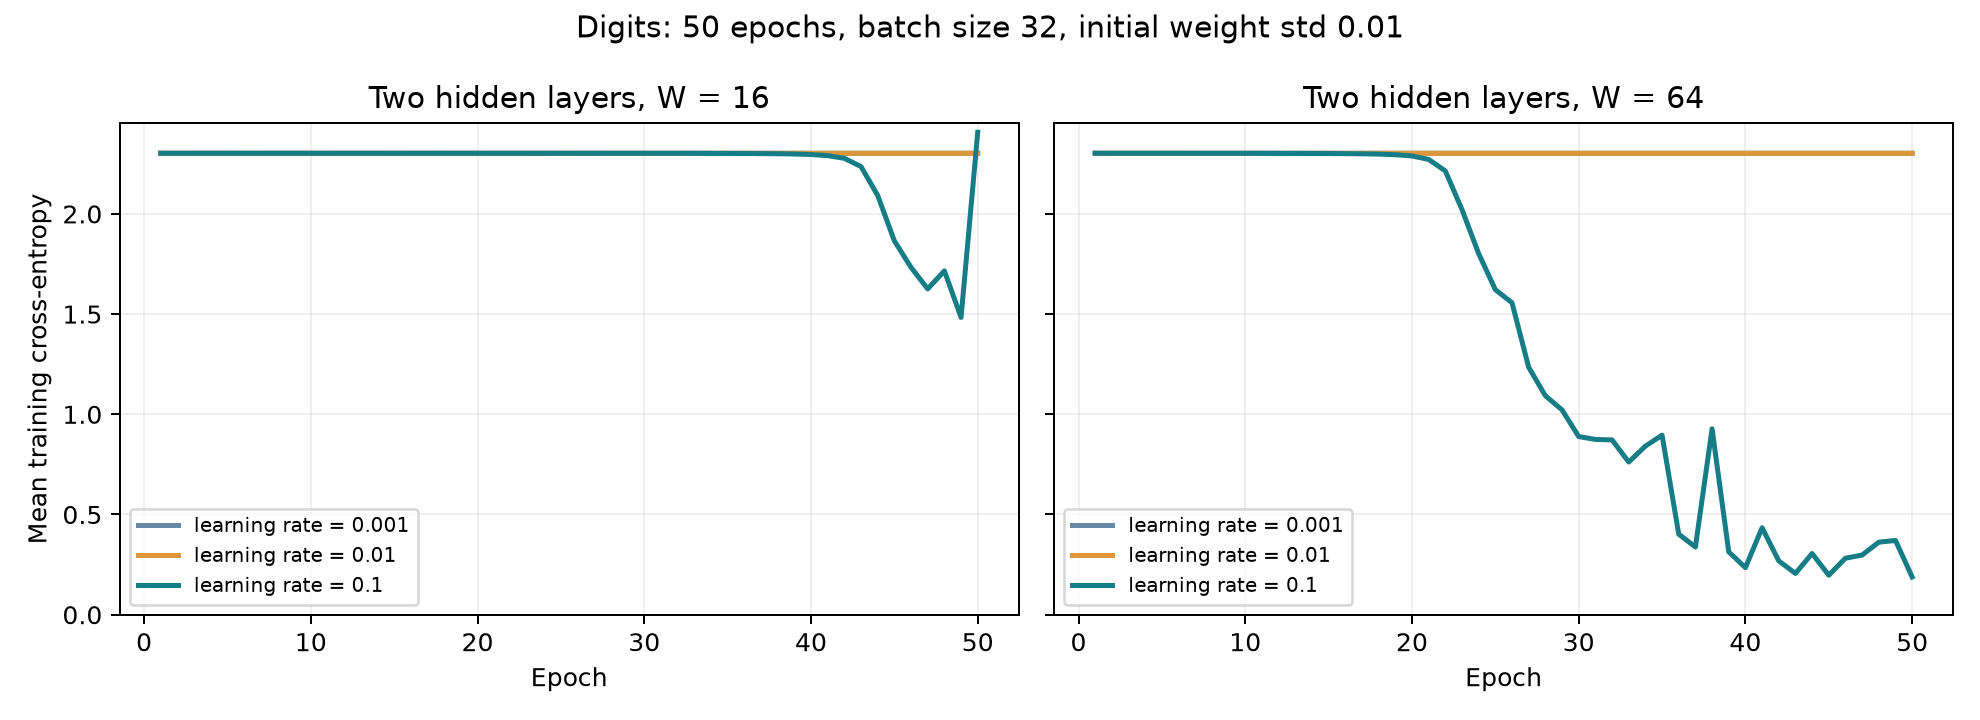

In [9]:
from IPython.display import Image, display
display(Image(filename='results/loss_curves.png'))

## 6. Interpretation

The highest observed test accuracy is **90.74%** (490/540) for W=64, learning rate 0.1. These are comparisons on the prescribed test split, not a validation-based hyperparameter selection procedure. One initialization per configuration does not establish a statistically reliable ranking.

Small initial weights and two ReLU layers yield small early hidden-layer gradients. Consequently small learning rates may remain close to the uniform-prediction loss during these 50 epochs. For W=16 and learning rate 0.1, a late loss spike leads to a final loss of 2.407343 and test accuracy of 23.89%, indicating unstable training in this configuration. Increasing width adds capacity, but improvement still depends on the learning rate and optimization progress.

For W=16, the passes are essentially tied (forward 0.0286 ms; backward 0.0287 ms); this small difference does not establish a meaningful timing advantage. For W=64, the **backward** pass takes longer (forward 0.0432 ms; backward 0.0541 ms).

Forward performs three matrix multiplications. Backward performs five: three weight-gradient products plus two products that propagate errors into hidden layers; no input gradient is needed. For batch size m, forward multiply-accumulate count is $m(64W+W^2+10W)$; backward count is $m(64W+2W^2+20W)$. These counts are 46,080 versus 59,392 for W=16, and 282,624 versus 434,176 for W=64. The hidden-to-hidden product grows quadratically with W. Softmax, masks, reductions, allocations, and function-call overhead also affect the measured times, so the runtime ratio need not equal the multiplication-count ratio.

Evidence files: `results/gradient_check.csv`, `results/loss_curves.png`, `results/timing.csv`, `results/epoch_logs.csv`, `results/summary.csv`, and `results/results.json`.